# Manipulador planar 2R "acostado" con garra: DH, cinemática, cálculos y animación

Proyecto de Control de Manipuladores Robóticos. **Todos los valores son supuestos**: cámbialos en la celda de parámetros.

- Dos articulaciones de giro con **ejes verticales**: el brazo se mueve solo en el plano horizontal (no sube).
- L1 = 15 cm, L2 = 13 cm. L2 llega hasta el **centro de agarre (TCP)** de la garra.
- La garra es el efector final y se acciona aparte: **no cuenta como grado de libertad del brazo**.
- El envase se **arrastra** sobre la mesa (el brazo no lo levanta).

Ejecuta las celdas en orden (Entorno de ejecución → Ejecutar todo).

In [33]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

plt.rcParams['animation.embed_limit'] = 60   # MB, límite para la animación embebida
sp.init_printing()

# ---------- PARÁMETROS GEOMÉTRICOS (m) ----------
L1 = 0.15      # eslabón 1: eje de la base -> eje del codo
L2 = 0.13      # eslabón 2: eje del codo -> centro de agarre de la garra (TCP)
H  = 0.03      # altura constante del plano del brazo sobre la mesa

# ---------- GARRA (efector final) ----------
G_LEN    = 0.03          # largo de los dedos
D_ENVASE = 0.03          # diámetro del envase (~30 ml)
G_CLOSED = D_ENVASE/2    # semiabertura con el envase agarrado
G_OPEN   = 0.025         # semiabertura con la garra abierta

R_MIN, R_MAX = abs(L1 - L2), L1 + L2
print(f"Espacio de trabajo: corona con {R_MIN*100:.0f} cm <= r <= {R_MAX*100:.0f} cm")

Espacio de trabajo: corona con 2 cm <= r <= 28 cm


## Punto 2: parámetros DH y matrices de transformación

Ambos ejes de giro son verticales (z0 ∥ z1 ∥ z2), por eso α = 0 en los dos eslabones.

| i | θᵢ | dᵢ | aᵢ | αᵢ |
|---|----|----|----|----|
| 1 | q1 | h  | L1 | 0  |
| 2 | q2 | 0  | L2 | 0  |

Matriz DH estándar: Aᵢ = Rz(θ)·Tz(d)·Tx(a)·Rx(α).

In [34]:
# ---------- Matrices simbólicas (para pegar en el informe) ----------
q1s, q2s, hs, L1s, L2s = sp.symbols('q1 q2 h L1 L2', real=True)

def dh_sym(th, d, a, al):
    ct, st, ca, sa = sp.cos(th), sp.sin(th), sp.cos(al), sp.sin(al)
    return sp.Matrix([[ct, -st*ca,  st*sa, a*ct],
                      [st,  ct*ca, -ct*sa, a*st],
                      [0,   sa,     ca,    d   ],
                      [0,   0,      0,     1   ]])

A1 = dh_sym(q1s, hs, L1s, 0)
A2 = dh_sym(q2s, 0,  L2s, 0)
T02 = sp.simplify(A1 * A2)

print("A1 (base -> codo):");            display(A1)
print("A2 (codo -> herramienta):");     display(A2)
print("T02 = A1 * A2 (cinemática directa):"); display(T02)

A1 (base -> codo):


⎡cos(q₁)  -sin(q₁)  0  L₁⋅cos(q₁)⎤
⎢                                ⎥
⎢sin(q₁)  cos(q₁)   0  L₁⋅sin(q₁)⎥
⎢                                ⎥
⎢   0        0      1      h     ⎥
⎢                                ⎥
⎣   0        0      0      1     ⎦

A2 (codo -> herramienta):


⎡cos(q₂)  -sin(q₂)  0  L₂⋅cos(q₂)⎤
⎢                                ⎥
⎢sin(q₂)  cos(q₂)   0  L₂⋅sin(q₂)⎥
⎢                                ⎥
⎢   0        0      1      0     ⎥
⎢                                ⎥
⎣   0        0      0      1     ⎦

T02 = A1 * A2 (cinemática directa):


⎡cos(q₁ + q₂)  -sin(q₁ + q₂)  0  L₁⋅cos(q₁) + L₂⋅cos(q₁ + q₂)⎤
⎢                                                            ⎥
⎢sin(q₁ + q₂)  cos(q₁ + q₂)   0  L₁⋅sin(q₁) + L₂⋅sin(q₁ + q₂)⎥
⎢                                                            ⎥
⎢     0              0        1               h              ⎥
⎢                                                            ⎥
⎣     0              0        0               1              ⎦

In [35]:
# ---------- Funciones numéricas ----------
def dh(th, d, a, al):
    ct, st, ca, sa = np.cos(th), np.sin(th), np.cos(al), np.sin(al)
    return np.array([[ct, -st*ca,  st*sa, a*ct],
                     [st,  ct*ca, -ct*sa, a*st],
                     [0,   sa,     ca,    d   ],
                     [0,   0,      0,     1   ]])

def fk_dh(q):
    # Cinemática directa por producto de matrices DH.
    # Devuelve T02 y los orígenes de {0}, {1}, {2} (base, codo, TCP) para dibujar.
    A1 = dh(q[0], H,   L1, 0.0)
    A2 = dh(q[1], 0.0, L2, 0.0)
    T02 = A1 @ A2
    J = np.array([[0.0, 0.0, H], A1[:3, 3], T02[:3, 3]])
    return T02, J

def fk_closed(q):
    # Cinemática directa en forma cerrada (para comparar con la de DH).
    return np.array([L1*np.cos(q[0]) + L2*np.cos(q[0] + q[1]),
                     L1*np.sin(q[0]) + L2*np.sin(q[0] + q[1]),
                     H])

def ik_2r(p, codo=+1):
    # Cinemática inversa geométrica. codo=+1 -> q2>0 | codo=-1 -> q2<0
    x, y = p[0], p[1]
    D = (x**2 + y**2 - L1**2 - L2**2) / (2*L1*L2)
    if abs(D) > 1:
        raise ValueError(f"Punto ({x:.3f}, {y:.3f}) fuera del espacio de trabajo (|D|={abs(D):.3f})")
    q2 = np.arctan2(codo*np.sqrt(1 - D**2), D)
    q1 = np.arctan2(y, x) - np.arctan2(L2*np.sin(q2), L1 + L2*np.cos(q2))
    return np.array([q1, q2])

## Punto 3: cálculos de posición de la herramienta

Se definen los puntos de la tarea, se resuelve la cinemática inversa y se verifica volviendo a la directa.

In [36]:
codo = +1   # +1: codo a la izquierda (q2>0)

W = np.array([[0.20,  0.00],    # home
              [0.22,  0.10],    # envase (agarre)
              [0.10, -0.17],    # destino (suelta)
              [0.20,  0.00]])   # home
nombres = ['Home', 'Envase (agarre)', 'Destino (suelta)', 'Home']

filas = []
for nom, w in zip(nombres, W):
    qi = ik_2r(w, codo)
    T, _ = fk_dh(qi)
    filas.append({'Punto': nom,
                  'x_obj [m]': w[0], 'y_obj [m]': w[1], 'r [m]': np.hypot(*w),
                  'q1 [°]': np.degrees(qi[0]), 'q2 [°]': np.degrees(qi[1]),
                  'x_FK [m]': T[0, 3], 'y_FK [m]': T[1, 3],
                  'error [m]': np.hypot(T[0, 3] - w[0], T[1, 3] - w[1])})
df = pd.DataFrame(filas)
err = df['error [m]'].map(lambda v: f"{v:.1e}")
df = df.round(4)
df['error [m]'] = err
display(df)

# Prueba masiva IK <-> FK con 500 configuraciones aleatorias
rng = np.random.default_rng(0)
err_q = 0.0
for _ in range(500):
    qr = np.radians([rng.uniform(-100, 100), rng.uniform(10, 150)])
    pr = fk_closed(qr)
    err_q = max(err_q, np.abs(ik_2r(pr[:2], +1) - qr).max())
print(f"Error máx. |q_IK - q| en 500 pruebas aleatorias: {err_q:.2e} rad")

,Punto,x_obj [m],y_obj [m],r [m],q1 [°],q2 [°],x_FK [m],y_FK [m],error [m]
0,Home,0.20,0.00,0.2000,-40.5358,89.1185,0.20,0.00,0.0e+00
1,Envase (agarre),0.22,0.10,0.2417,-3.5765,60.8446,0.22,0.10,3.1e-17
2,Destino (suelta),0.10,-0.17,0.1972,-100.7636,90.7346,0.10,-0.17,0.0e+00
3,Home,0.20,0.00,0.2000,-40.5358,89.1185,0.20,0.00,0.0e+00


Error máx. |q_IK - q| en 500 pruebas aleatorias: 3.89e-15 rad


## Trayectoria de la tarea

Tres movimientos en **línea recta** en el plano (perfil quíntico: velocidad y aceleración nulas en los extremos),
con la cinemática inversa aplicada en cada instante. En el envase y en el destino el brazo se detiene 0,6 s
mientras la garra se cierra o se abre.

In [37]:
DT, T_MOV, T_DWELL = 0.02, 1.5, 0.6
n_mov = int(round(T_MOV / DT)) + 1
n_dw  = int(round(T_DWELL / DT))

def quintico(tau):
    return 10*tau**3 - 15*tau**4 + 6*tau**5

def mover(a, b):
    s = quintico(np.linspace(0, 1, n_mov))[:, None]
    return a + s * (b - a)

def esperar(a, n):
    return np.tile(a, (n, 1))

home, pick, place = W[0], W[1], W[2]

# (posición TCP, semiabertura de la garra, modo del envase: 0=en origen, 1=con la herramienta, 2=en destino)
tramos = [
    (mover(home, pick),  np.full(n_mov, G_OPEN),               np.zeros(n_mov, int)),      # ir al envase
    (esperar(pick, n_dw),  np.linspace(G_OPEN, G_CLOSED, n_dw), np.zeros(n_dw, int)),      # cerrar garra
    (mover(pick, place), np.full(n_mov, G_CLOSED),             np.ones(n_mov, int)),       # trasladar
    (esperar(place, n_dw), np.linspace(G_CLOSED, G_OPEN, n_dw), np.full(n_dw, 2)),         # abrir garra
    (mover(place, home), np.full(n_mov, G_OPEN),               np.full(n_mov, 2)),         # volver
]
Xd   = np.vstack([t[0] for t in tramos])           # trayectoria cartesiana deseada
Wg   = np.concatenate([t[1] for t in tramos])      # semiabertura de la garra
modo = np.concatenate([t[2] for t in tramos])
N = len(Xd)
t = np.arange(N) * DT

Q = np.array([ik_2r(x, codo) for x in Xd])         # ángulos articulares
Pc = np.where(modo[:, None] == 0, pick, np.where(modo[:, None] == 1, Xd, place))  # posición del envase

print(f"{N} muestras, duración {t[-1]:.1f} s")
print("q1 [°]: min %.1f  max %.1f" % tuple(np.degrees([Q[:, 0].min(), Q[:, 0].max()])))
print("q2 [°]: min %.1f  max %.1f" % tuple(np.degrees([Q[:, 1].min(), Q[:, 1].max()])))

288 muestras, duración 5.7 s
q1 [°]: min -100.8  max -3.6
q2 [°]: min 60.8  max 110.5


## Punto 4: simulación animada

Se dibuja el brazo (base → codo → TCP), la garra en forma de "U" que se abre y se cierra, el envase y el rastro.
Durante el cálculo de la animación se **lee la posición del TCP directamente del gráfico** para compararla luego con los cálculos.

Posiciones leídas del gráfico animado: (288, 2)


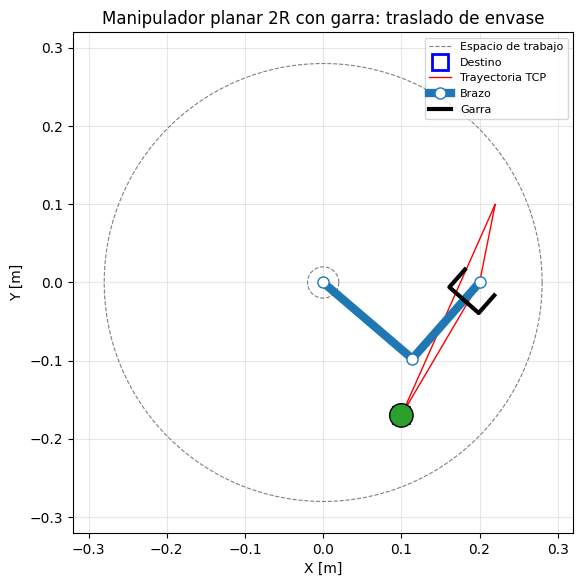

In [43]:
def garra_puntos(tcp, phi, w):
    # Polilínea en "U": punta dedo A -> base dedo A -> base dedo B -> punta dedo B
    u = np.array([np.cos(phi), np.sin(phi)])
    n = np.array([-u[1], u[0]])
    c = tcp - G_LEN * u
    A0, B0 = c + w*n, c - w*n
    return np.array([A0 + G_LEN*u, A0, B0, B0 + G_LEN*u])

TCP = np.array([fk_dh(q)[0][:2, 3] for q in Q])    # para el rastro

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
ax.set_xlim(-0.32, 0.32); ax.set_ylim(-0.32, 0.32)
ax.set_xlabel('X [m]'); ax.set_ylabel('Y [m]')
ax.set_title('Manipulador planar 2R con garra: traslado de envase')
th = np.linspace(0, 2*np.pi, 300)
ax.plot(R_MAX*np.cos(th), R_MAX*np.sin(th), '--', color='gray', lw=0.8, label='Espacio de trabajo')
ax.plot(R_MIN*np.cos(th), R_MIN*np.sin(th), '--', color='gray', lw=0.8)
ax.plot(*place, 'bs', ms=12, mfc='none', mew=2, label='Destino')
traza, = ax.plot([], [], 'r-', lw=1, label='Trayectoria TCP')
arm,   = ax.plot([], [], '-o', lw=6, color='tab:blue', mfc='w', ms=8, label='Brazo')
garra, = ax.plot([], [], '-', lw=3, color='k', label='Garra')
envase = plt.Circle(pick, D_ENVASE/2, fc='tab:green', ec='k', zorder=5)
ax.add_patch(envase)
ax.legend(loc='upper right', fontsize=8)

def dibujar(k):
    T, J = fk_dh(Q[k])
    tcp, phi = T[:2, 3], Q[k, 0] + Q[k, 1]
    arm.set_data(J[:, 0], J[:, 1])
    gp = garra_puntos(tcp, phi, Wg[k])
    garra.set_data(gp[:, 0], gp[:, 1])
    envase.center = Pc[k]
    traza.set_data(TCP[:k+1, 0], TCP[:k+1, 1])
    return arm, garra, envase, traza

# Se dibuja cada cuadro y se lee la posición del TCP desde el gráfico
p_anim = np.zeros((N, 2))
for k in range(N):
    dibujar(k)
    p_anim[k] = [arm.get_xdata()[-1], arm.get_ydata()[-1]]
print("Posiciones leídas del gráfico animado:", p_anim.shape)

In [44]:
anim = FuncAnimation(fig, dibujar, frames=range(0, N, 3), interval=60, blit=False)
plt.close(fig)                  # evita mostrar el gráfico estático duplicado
HTML(anim.to_jshtml())          # reproductor de la animación en el notebook

### Figura estática para el informe
Trayectoria del TCP y poses del brazo en el inicio, el agarre y la suelta.

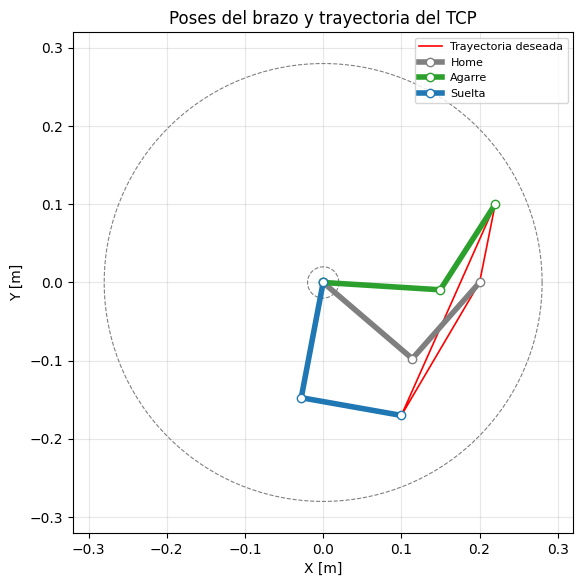

In [40]:
idx_pick  = n_mov - 1
idx_place = n_mov + n_dw + n_mov - 1
fig2, ax2 = plt.subplots(figsize=(6.5, 6.5))
ax2.set_aspect('equal'); ax2.grid(True, alpha=0.3)
ax2.set_xlim(-0.32, 0.32); ax2.set_ylim(-0.32, 0.32)
ax2.set_xlabel('X [m]'); ax2.set_ylabel('Y [m]')
ax2.set_title('Poses del brazo y trayectoria del TCP')
ax2.plot(R_MAX*np.cos(th), R_MAX*np.sin(th), '--', color='gray', lw=0.8)
ax2.plot(R_MIN*np.cos(th), R_MIN*np.sin(th), '--', color='gray', lw=0.8)
ax2.plot(Xd[:, 0], Xd[:, 1], 'r-', lw=1.2, label='Trayectoria deseada')
for k, c, lab in [(0, 'tab:gray', 'Home'), (idx_pick, 'tab:green', 'Agarre'), (idx_place, 'tab:blue', 'Suelta')]:
    _, J = fk_dh(Q[k])
    ax2.plot(J[:, 0], J[:, 1], '-o', lw=4, color=c, mfc='w', label=lab)
ax2.legend(loc='upper right', fontsize=8)
plt.show()

## Comparativas: animación vs cálculos

1. Posición del TCP por **producto de matrices DH** vs **fórmula cerrada**.
2. Posición **leída del gráfico animado** vs cálculo.
3. **FK(IK(trayectoria))** vs trayectoria deseada.
4. Efecto de la **resolución del encoder** (cuantización de q) en la posición de la herramienta.

Los tres primeros errores deben ser ruido numérico (~1e-16 m).

Máx. error DH vs fórmula cerrada          : 5.55e-17 m
Máx. error animación vs cálculo           : 5.55e-17 m
Máx. error FK(IK) vs trayectoria deseada  : 6.21e-17 m
Máx. error por cuantización del encoder   : 0.415 mm  (resolución 0.150°)


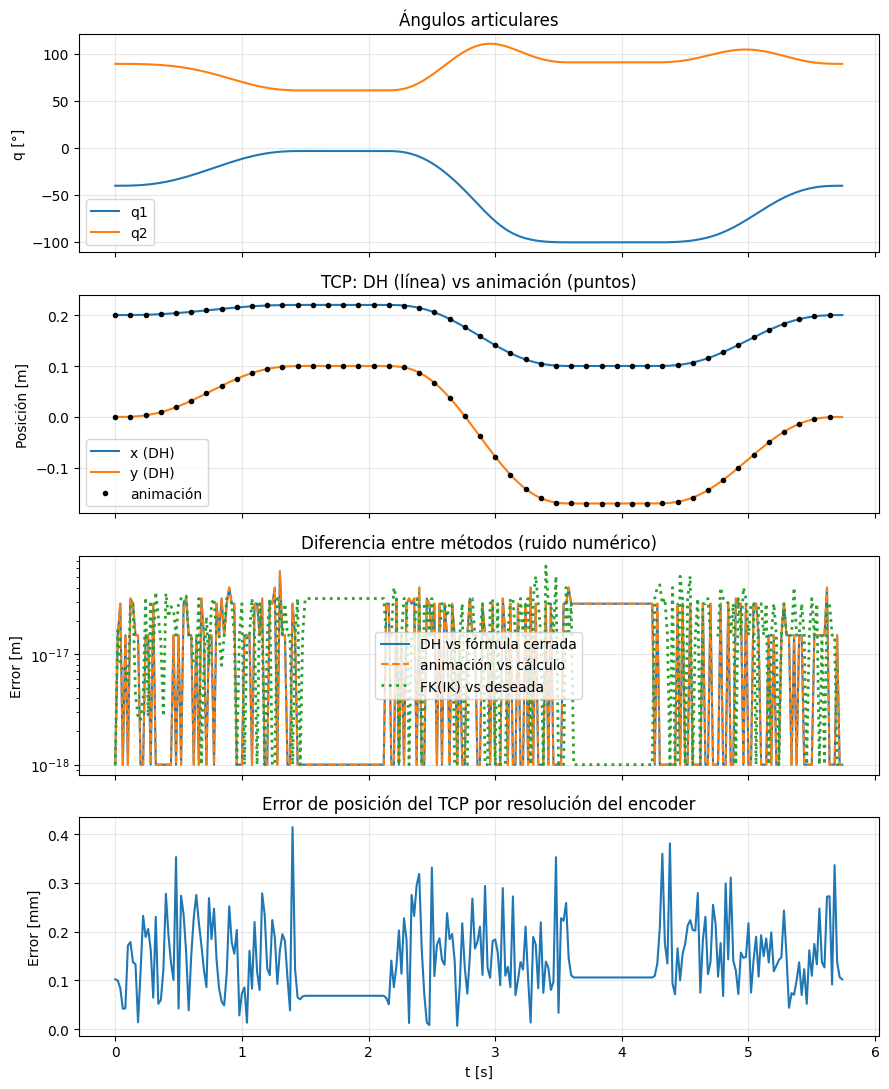

In [41]:
p_dh = np.array([fk_dh(q)[0][:2, 3] for q in Q])
p_cf = np.array([fk_closed(q)[:2] for q in Q])

e_dh_cf   = np.linalg.norm(p_dh   - p_cf, axis=1)
e_anim_cf = np.linalg.norm(p_anim - p_cf, axis=1)
e_traj    = np.linalg.norm(p_dh   - Xd,   axis=1)

CPR = 2400                       # cuentas por vuelta de la articulación (supuesto)
res = 2*np.pi / CPR
Qenc  = np.round(Q / res) * res
p_enc = np.array([fk_closed(q)[:2] for q in Qenc])
e_enc = np.linalg.norm(p_enc - p_cf, axis=1) * 1e3      # mm

print(f"Máx. error DH vs fórmula cerrada          : {e_dh_cf.max():.2e} m")
print(f"Máx. error animación vs cálculo           : {e_anim_cf.max():.2e} m")
print(f"Máx. error FK(IK) vs trayectoria deseada  : {e_traj.max():.2e} m")
print(f"Máx. error por cuantización del encoder   : {e_enc.max():.3f} mm  (resolución {np.degrees(res):.3f}°)")

fig3, axs = plt.subplots(4, 1, figsize=(9, 11), sharex=True)
axs[0].plot(t, np.degrees(Q[:, 0]), label='q1'); axs[0].plot(t, np.degrees(Q[:, 1]), label='q2')
axs[0].set_ylabel('q [°]'); axs[0].set_title('Ángulos articulares'); axs[0].legend(); axs[0].grid(alpha=0.3)

axs[1].plot(t, p_dh[:, 0], label='x (DH)'); axs[1].plot(t, p_dh[:, 1], label='y (DH)')
axs[1].plot(t[::6], p_anim[::6, 0], 'k.', label='animación'); axs[1].plot(t[::6], p_anim[::6, 1], 'k.')
axs[1].set_ylabel('Posición [m]'); axs[1].set_title('TCP: DH (línea) vs animación (puntos)')
axs[1].legend(); axs[1].grid(alpha=0.3)

axs[2].semilogy(t, e_dh_cf + 1e-18, label='DH vs fórmula cerrada')
axs[2].semilogy(t, e_anim_cf + 1e-18, '--', label='animación vs cálculo')
axs[2].semilogy(t, e_traj + 1e-18, ':', lw=2, label='FK(IK) vs deseada')
axs[2].set_ylabel('Error [m]'); axs[2].set_title('Diferencia entre métodos (ruido numérico)')
axs[2].legend(); axs[2].grid(alpha=0.3)

axs[3].plot(t, e_enc)
axs[3].set_ylabel('Error [mm]'); axs[3].set_xlabel('t [s]')
axs[3].set_title('Error de posición del TCP por resolución del encoder'); axs[3].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### (Opcional) Guardar la animación como GIF

In [42]:
from matplotlib.animation import PillowWriter
anim.save('brazo_2R.gif', writer=PillowWriter(fps=25))
try:
    from google.colab import files
    files.download('brazo_2R.gif')
except ImportError:
    print("Guardado como brazo_2R.gif")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>